# 03 — Exact fault-type diagnosis

            This notebook presents the saved multiclass diagnosis results. It does not retrain a model. Binary detection and fault-type diagnosis are separate tasks: first the system asks whether operation is normal or faulty; diagnosis then predicts the original fault label for fault-labelled rows.

            The current diagnosis artefacts are the pooled diagnosis experiment. Building-specific diagnosis is intentionally separate and should only be added when class support is sufficient.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'normal': '#457b9d', 'fault': '#e76f51', 'accent': '#2a9d8f', 'dark': '#264653'}

def find_root():
    for candidate in [Path.cwd(), Path.cwd().parent, Path('/Users/mili/Desktop/IRPN')]:
        if (candidate / 'pyproject.toml').exists() and (candidate / 'results').exists():
            return candidate
    raise FileNotFoundError('Open this notebook from the IRPN repository or set ROOT manually.')

ROOT = find_root()

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

def require(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError('Missing saved artefacts. Run the pipeline commands first:\n' + '\n'.join(missing))

def pct(value):
    return f'{100 * value:.1f}%' if pd.notna(value) else 'n/a'

## 1. Load and describe the diagnosis artefacts

In [2]:
RESULTS = ROOT / 'results' / 'diagnosis'
require(RESULTS / 'diagnosis_manifest.json', RESULTS / 'diagnosis_metrics_summary.csv', RESULTS / 'diagnosis_metrics_by_class.csv', RESULTS / 'diagnosis_confusion_matrix.csv')
manifest = read_json(RESULTS / 'diagnosis_manifest.json')
summary = pd.read_csv(RESULTS / 'diagnosis_metrics_summary.csv')
by_class = pd.read_csv(RESULTS / 'diagnosis_metrics_by_class.csv')
confusion = pd.read_csv(RESULTS / 'diagnosis_confusion_matrix.csv')
print('Feature variants:', manifest.get('feature_variants'))
print('Minimum fault rows:', manifest.get('minimum_fault_rows'))
print('Confidence threshold:', manifest.get('confidence_threshold'))
display(summary.round(3))

Feature variants: ['physical_signal']
Minimum fault rows: 30
Confidence threshold: 0.7


,design,fold,variant,task,evaluated_rows,unsupported_rows,all_test_rows,class_count,confidence_threshold,coverage,abstention_rate,confident_accuracy,accuracy,balanced_accuracy,macro_f1,weighted_f1,minimum_fault_rows,excluded_fault_rows
0,building_held_out,fold_001,physical_signal,fault_type,8974,44182,53156,4,0.7,0.998,0.002,0.998,0.997,0.995,0.991,0.997,30,1
1,building_held_out,fold_002,physical_signal,fault_type,12290,0,12290,4,0.7,0.997,0.003,0.369,0.368,0.763,0.329,0.317,30,1
2,building_held_out,fold_003,physical_signal,fault_type,56130,0,56130,4,0.7,0.993,0.007,0.730,0.725,0.546,0.344,0.768,30,1
3,chronological,fold_001,physical_signal,fault_type,20958,0,20958,6,0.7,0.985,0.015,0.989,0.979,0.973,0.866,0.981,30,1
4,nested_grouped,fold_001,physical_signal,fault_type,32473,0,32473,6,0.7,0.955,0.045,0.791,0.762,0.740,0.692,0.740,30,1
5,nested_grouped,fold_002,physical_signal,fault_type,19733,0,19733,6,0.7,0.985,0.015,0.994,0.984,0.868,0.877,0.983,30,1
6,nested_grouped,fold_003,physical_signal,fault_type,24433,0,24433,6,0.7,0.998,0.002,0.997,0.996,0.992,0.989,0.996,30,1
7,nested_grouped,fold_004,physical_signal,fault_type,22626,0,22626,6,0.7,0.997,0.003,0.992,0.990,0.996,0.991,0.990,30,1
8,nested_grouped,fold_005,physical_signal,fault_type,22311,0,22311,6,0.7,0.998,0.002,0.999,0.998,0.994,0.982,0.998,30,1


## 2. Overall diagnosis performance

In [3]:
overall = summary.groupby(['design', 'task'], as_index=False).agg(
    evaluated_rows=('evaluated_rows', 'sum'), unsupported_rows=('unsupported_rows', 'sum'),
    coverage=('coverage', 'mean'), macro_f1=('macro_f1', 'mean'), weighted_f1=('weighted_f1', 'mean'),
    confident_accuracy=('confident_accuracy', 'mean')
)
display(overall.round(3))

,design,task,evaluated_rows,unsupported_rows,coverage,macro_f1,weighted_f1,confident_accuracy
0,building_held_out,fault_type,77394,44182,0.996,0.555,0.694,0.699
1,chronological,fault_type,20958,0,0.985,0.866,0.981,0.989
2,nested_grouped,fault_type,121576,0,0.987,0.906,0.941,0.955


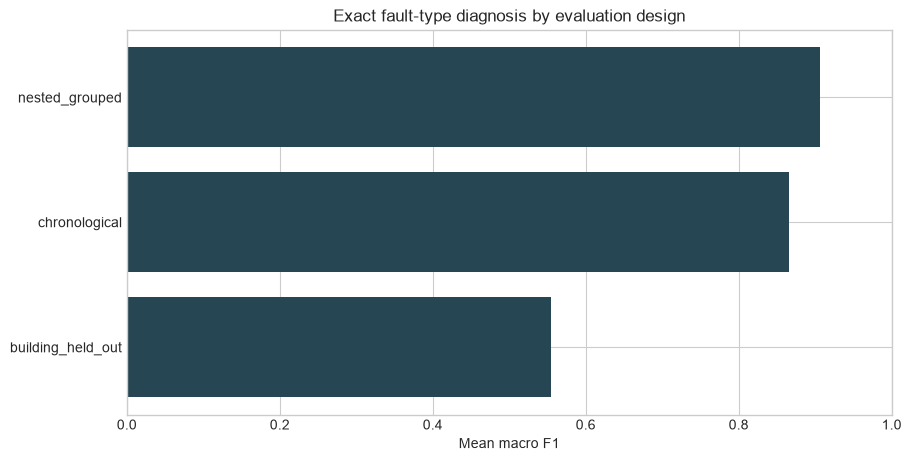

In [4]:
plot_data = overall[overall['task'].eq('fault_type')].sort_values('macro_f1')
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.barh(plot_data['design'], plot_data['macro_f1'], color=COLORS['dark'])
ax.set_xlim(0, 1)
ax.set_xlabel('Mean macro F1')
ax.set_title('Exact fault-type diagnosis by evaluation design')
plt.show()

Macro F1 gives each retained fault type equal importance. Weighted F1 reflects the row distribution and can be higher when common fault types are easier. `unsupported_rows` are reported separately when a class appears in evaluation but was absent from the training fold; they are not silently treated as ordinary model errors.

## 3. Fault-type performance

In [5]:
fault_classes = by_class[by_class['task'].eq('fault_type')].copy()
class_summary = fault_classes.groupby('class_label', as_index=False).agg(
    mean_f1=('f1', 'mean'), mean_precision=('precision', 'mean'), mean_recall=('recall', 'mean'), support=('support', 'sum')
).sort_values('mean_f1')
display(class_summary.round(3))

,class_label,mean_f1,mean_precision,mean_recall,support
5,Valve position fault,0.584,0.543,0.760,3942
3,Supply air temperature fault,0.760,0.754,0.876,3039
2,Return air temperature fault,0.793,0.899,0.803,37678
4,Supply fan fault,0.904,0.895,0.964,122945
1,Heating pump fault,0.946,0.919,0.992,32416
0,Cooling pump fault,1.000,1.000,1.000,19908


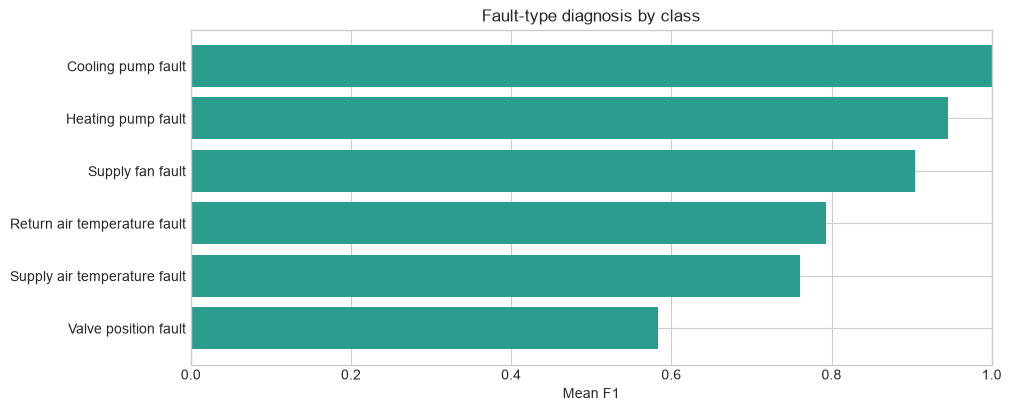

In [6]:
fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(class_summary))), constrained_layout=True)
ax.barh(class_summary['class_label'], class_summary['mean_f1'], color=COLORS['accent'])
ax.set_xlim(0, 1)
ax.set_xlabel('Mean F1')
ax.set_title('Fault-type diagnosis by class')
plt.show()

## 4. Confusion matrix

class_label,Valve position fault,Supply air temperature fault,Return air temperature fault,Supply fan fault,Heating pump fault,Cooling pump fault
class_label,,,,,,
Valve position fault,2256,2,1115,226,342,1
Supply air temperature fault,4,1983,731,319,1,1
Return air temperature fault,3425,1313,22756,7752,2432,0
Supply fan fault,2953,0,10723,108850,419,0
Heating pump fault,0,0,44,271,32101,0
Cooling pump fault,0,0,0,0,0,19908


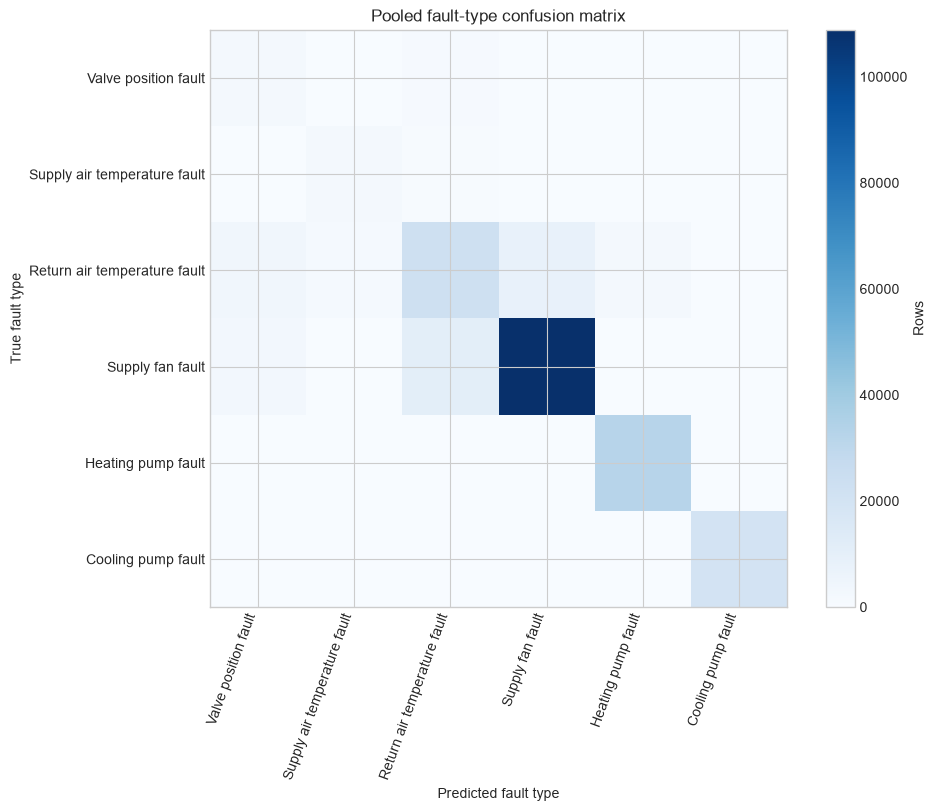

In [7]:
matrix = confusion[confusion['task'].eq('fault_type')].pivot_table(index='true_label', columns='predicted_label', values='count', aggfunc='sum', fill_value=0)
matrix = matrix.reindex(index=class_summary['class_label'], columns=class_summary['class_label'], fill_value=0)
display(matrix)
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
image = ax.imshow(matrix.to_numpy(), cmap='Blues')
ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=70, ha='right')
ax.set_yticks(range(len(matrix.index)), matrix.index)
ax.set_title('Pooled fault-type confusion matrix')
ax.set_xlabel('Predicted fault type')
ax.set_ylabel('True fault type')
fig.colorbar(image, ax=ax, label='Rows')
plt.show()

**Confidence caution.** The saved confidence is a model score used for the configured abstention rule; it is not automatically a calibrated probability. A diagnosis shown at the threshold should remain an inspection aid, not an automatic maintenance decision.

## 5. Diagnosis limitations and next evidence

In [8]:
limitations = pd.DataFrame([
    ['Task boundary', 'Diagnosis predicts fault types; it does not replace binary detection.'],
    ['Class support', 'Rare or unsupported classes are reported separately and should not be over-interpreted.'],
    ['Generalisation', 'These are pooled diagnosis outputs; building-specific diagnosis requires a separate class-support check.'],
    ['Confidence', 'The threshold provides abstention, not a calibrated probability.'],
], columns=['issue', 'interpretation'])
display(limitations)

,issue,interpretation
0,Task boundary,Diagnosis predicts fault types; it does not re...
1,Class support,Rare or unsupported classes are reported separ...
2,Generalisation,These are pooled diagnosis outputs; building-s...
3,Confidence,"The threshold provides abstention, not a calib..."
